# Olist EDA: late deliveries and reviews

Run the cells from top to bottom. Keep this file in the same folder as `olist.db`.

After each chart, double-click the **This tells me** cell and write one line in your own words.

In [2]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("olist.db")
os.makedirs("charts", exist_ok=True)

## 1. Reviews: how many of each score?

In [3]:
query = """
select review_score, count(*) as total_reviews
from order_reviews
group by review_score
order by review_score
"""
scores = pd.read_sql(query, conn)
scores

,review_score,total_reviews
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


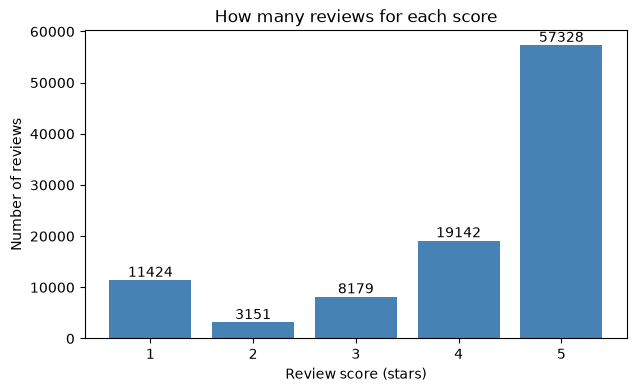

In [4]:
plt.figure(figsize=(7, 4))
bars = plt.bar(scores["review_score"], scores["total_reviews"], color="steelblue")
plt.bar_label(bars)
plt.title("How many reviews for each score")
plt.xlabel("Review score (stars)")
plt.ylabel("Number of reviews")
plt.savefig("charts/1_review_scores.png", bbox_inches="tight")
plt.show()

**This tells me:** (write one line here)

## 2. The overall late rate (we use it as a reference line)

In [5]:
query = """
select
    count(*) as delivered_orders,
    sum(case when date(order_delivered_customer_date) > date(order_estimated_delivery_date) then 1 else 0 end) as late_orders
from orders
where order_status = 'delivered'
  and order_delivered_customer_date is not null
"""
overall = pd.read_sql(query, conn)
overall_late_percent = 100 * overall["late_orders"].iloc[0] / overall["delivered_orders"].iloc[0]

print("delivered orders:", overall["delivered_orders"].iloc[0])
print("late orders:", overall["late_orders"].iloc[0])
print("late percent:", round(overall_late_percent, 1))

delivered orders: 96470
late orders: 6534
late percent: 6.8


Check: this should match query 3 in SQL (96,470 delivered, 6,534 late, 6.8%).

## 3. Review score by delivery time

In [6]:
query = """
with review_per_order as (
    select order_id, avg(review_score) as review_score
    from order_reviews
    group by order_id
),
delivery as (
    select
        order_id,
        julianday(date(order_delivered_customer_date)) - julianday(date(order_estimated_delivery_date)) as days_late
    from orders
    where order_status = 'delivered'
      and order_delivered_customer_date is not null
)
select
    case
        when d.days_late <= 0 then '1. on time or early'
        when d.days_late <= 3 then '2. 1-3 days late'
        when d.days_late <= 7 then '3. 4-7 days late'
        else '4. more than 7 days late'
    end as delivery_group,
    count(*) as total_orders,
    round(avg(r.review_score), 2) as avg_review_score
from delivery d
join review_per_order r on d.order_id = r.order_id
group by delivery_group
order by delivery_group
"""
by_delay = pd.read_sql(query, conn)
by_delay

,delivery_group,total_orders,avg_review_score
0,1. on time or early,89443,4.29
1,2. 1-3 days late,1852,3.29
2,3. 4-7 days late,1748,2.11
3,4. more than 7 days late,2781,1.70


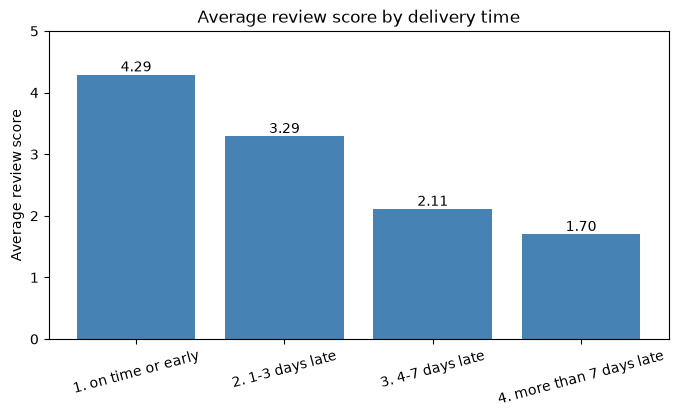

In [7]:
plt.figure(figsize=(8, 4))
bars = plt.bar(by_delay["delivery_group"], by_delay["avg_review_score"], color="steelblue")
plt.bar_label(bars, fmt="%.2f")
plt.title("Average review score by delivery time")
plt.ylabel("Average review score")
plt.ylim(0, 5)
plt.xticks(rotation=15)
plt.savefig("charts/2_review_by_delay.png", bbox_inches="tight")
plt.show()

**This tells me:** (write one line here)

## 4. Late rate by month

In [8]:
query = """
select
    strftime('%Y-%m', order_purchase_timestamp) as month,
    count(*) as delivered_orders,
    round(100.0 * sum(case when date(order_delivered_customer_date) > date(order_estimated_delivery_date) then 1 else 0 end) / count(*), 1) as late_percent
from orders
where order_status = 'delivered'
  and order_delivered_customer_date is not null
group by month
having count(*) >= 100
order by month
"""
monthly = pd.read_sql(query, conn)
monthly

,month,delivered_orders,late_percent
0,2016-10,265,0.8
1,2017-01,750,2.9
2,2017-02,1653,3.0
3,2017-03,2546,4.6
4,2017-04,2303,6.6
5,2017-05,3545,3.0
6,2017-06,3135,3.0
7,2017-07,3872,2.8
8,2017-08,4193,2.9
9,2017-09,4150,4.4


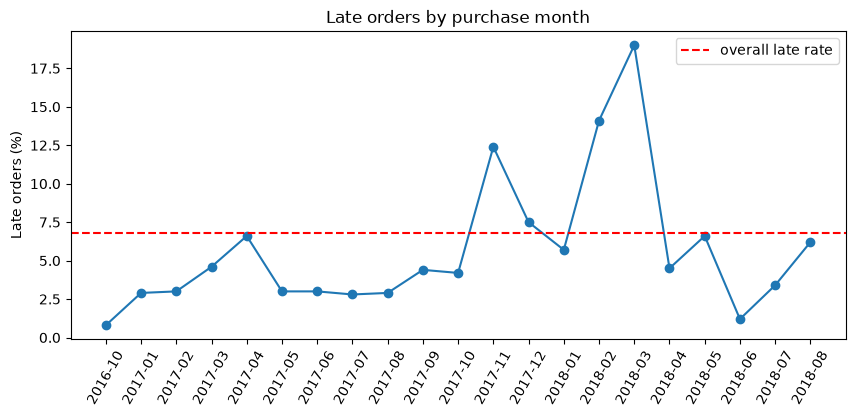

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(monthly["month"], monthly["late_percent"], marker="o")
plt.axhline(overall_late_percent, color="red", linestyle="--", label="overall late rate")
plt.xticks(rotation=60)
plt.title("Late orders by purchase month")
plt.ylabel("Late orders (%)")
plt.legend()
plt.savefig("charts/3_late_by_month.png", bbox_inches="tight")
plt.show()

**This tells me:** (write one line here)

## 5. Late rate by customer state

In [10]:
query = """
select
    customer_state,
    count(*) as delivered_orders,
    sum(case when date(order_delivered_customer_date) > date(order_estimated_delivery_date) then 1 else 0 end) as late_orders,
    round(100.0 * sum(case when date(order_delivered_customer_date) > date(order_estimated_delivery_date) then 1 else 0 end) / count(*), 1) as late_percent
from orders o
join customers c on o.customer_id = c.customer_id
where order_status = 'delivered'
  and order_delivered_customer_date is not null
group by customer_state
having count(*) >= 100
order by late_percent desc
"""
states = pd.read_sql(query, conn)
states

,customer_state,delivered_orders,late_orders,late_percent
0,AL,397,85,21.4
1,MA,717,125,17.4
2,SE,335,51,15.2
3,PI,476,66,13.9
4,CE,1279,176,13.8
5,BA,3256,396,12.2
6,RJ,12350,1495,12.1
7,PA,946,106,11.2
8,ES,1995,214,10.7
9,PB,517,54,10.4


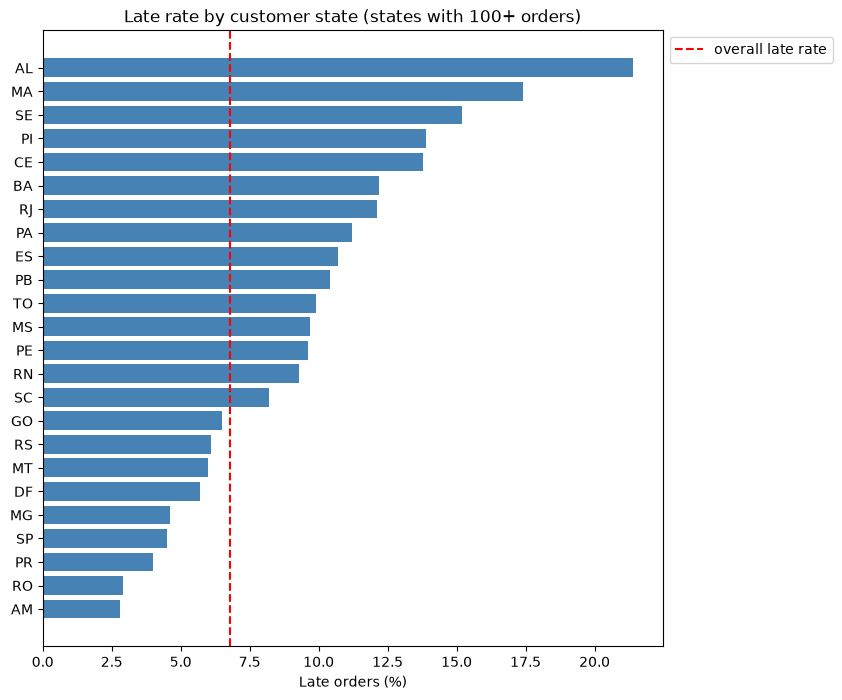

In [11]:
plt.figure(figsize=(8, 8))
plt.barh(states["customer_state"], states["late_percent"], color="steelblue")
plt.axvline(overall_late_percent, color="red", linestyle="--", label="overall late rate")
plt.gca().invert_yaxis()
plt.title("Late rate by customer state (states with 100+ orders)")
plt.xlabel("Late orders (%)")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.savefig("charts/4_late_by_state.png", bbox_inches="tight")
plt.show()

**This tells me:** (write one line here)

## 6. Rate vs volume: which states have the most late orders?

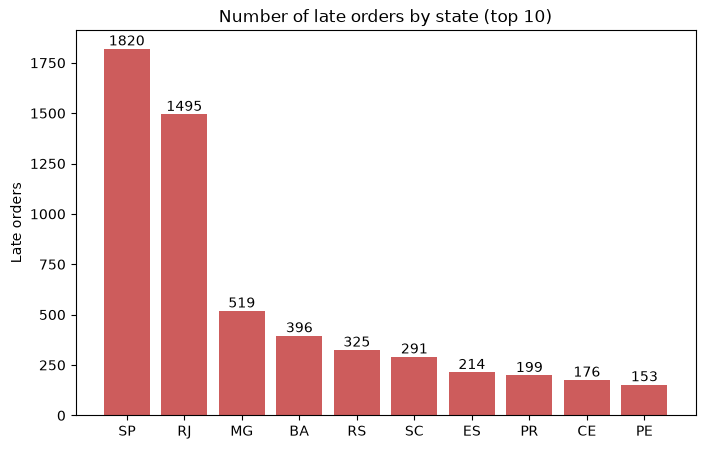

In [12]:
top_late = states.sort_values("late_orders", ascending=False).head(10)

plt.figure(figsize=(8, 5))
bars = plt.bar(top_late["customer_state"], top_late["late_orders"], color="indianred")
plt.bar_label(bars)
plt.title("Number of late orders by state (top 10)")
plt.ylabel("Late orders")
plt.savefig("charts/5_late_orders_by_state.png", bbox_inches="tight")
plt.show()

**This tells me:** (write one line here)

## 7. Late rate for the 10 biggest product categories

In [13]:
query = """
select
    coalesce(t.product_category_name_english, p.product_category_name, 'unknown') as category,
    count(distinct o.order_id) as delivered_orders,
    count(distinct case when date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) then o.order_id end) as late_orders,
    round(100.0 * count(distinct case when date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) then o.order_id end) / count(distinct o.order_id), 1) as late_percent
from orders o
join order_items i on o.order_id = i.order_id
join products p on i.product_id = p.product_id
left join category_translation t on p.product_category_name = t.product_category_name
where o.order_status = 'delivered'
  and o.order_delivered_customer_date is not null
group by category
order by delivered_orders desc
limit 10
"""
categories = pd.read_sql(query, conn)
categories

,category,delivered_orders,late_orders,late_percent
0,bed_bath_table,9272,689,7.4
1,health_beauty,8647,649,7.5
2,sports_leisure,7529,495,6.6
3,computers_accessories,6529,417,6.4
4,furniture_decor,6307,449,7.1
5,housewares,5743,308,5.4
6,watches_gifts,5493,406,7.4
7,telephony,4093,291,7.1
8,auto,3809,278,7.3
9,toys,3803,243,6.4


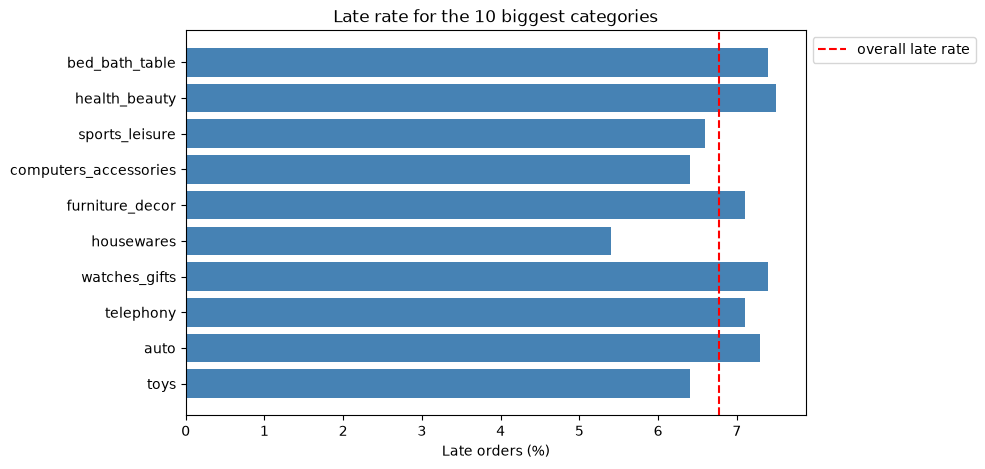

In [14]:
plt.figure(figsize=(8, 5))
plt.barh(categories["category"], categories["late_percent"], color="steelblue")
plt.axvline(overall_late_percent, color="red", linestyle="--", label="overall late rate")
plt.gca().invert_yaxis()
plt.title("Late rate for the 10 biggest categories")
plt.xlabel("Late orders (%)")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.savefig("charts/6_late_by_category.png", bbox_inches="tight")
plt.show()

**This tells me:** (write one line here)

## 8. Build one clean table for the dashboard

One row per delivered order. Tableau will use this file in the dashboard step.

In [15]:
query = """
with review_per_order as (
    select order_id, avg(review_score) as review_score
    from order_reviews
    group by order_id
),
order_value as (
    select order_id, sum(price + freight_value) as order_total
    from order_items
    group by order_id
)
select
    o.order_id,
    strftime('%Y-%m', o.order_purchase_timestamp) as purchase_month,
    c.customer_state,
    julianday(date(o.order_delivered_customer_date)) - julianday(date(o.order_estimated_delivery_date)) as days_late,
    r.review_score,
    v.order_total
from orders o
join customers c on o.customer_id = c.customer_id
left join review_per_order r on o.order_id = r.order_id
left join order_value v on o.order_id = v.order_id
where o.order_status = 'delivered'
  and o.order_delivered_customer_date is not null
"""
orders = pd.read_sql(query, conn)


def get_delivery_group(days_late):
    if days_late <= 0:
        return "1. on time or early"
    if days_late <= 3:
        return "2. 1-3 days late"
    if days_late <= 7:
        return "3. 4-7 days late"
    return "4. more than 7 days late"


orders["delivery_group"] = orders["days_late"].apply(get_delivery_group)
orders["is_late"] = (orders["days_late"] > 0).astype(int)
orders["bad_review"] = (orders["review_score"] <= 2).astype(int)

print("rows:", len(orders))
orders.head()

rows: 96470


,order_id,purchase_month,customer_state,days_late,review_score,order_total,delivery_group,is_late,bad_review
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10,SP,-8.0,4.0,38.71,1. on time or early,0,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07,BA,-6.0,4.0,141.46,1. on time or early,0,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08,GO,-18.0,5.0,179.12,1. on time or early,0,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11,RN,-13.0,5.0,72.20,1. on time or early,0,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02,SP,-10.0,5.0,28.62,1. on time or early,0,0


Checks. Run the next cell. You should see:
- rows: 96,470 (above)
- late and unhappy orders: 3,979
- money at risk: 720,475.17

These are the same numbers as SQL query 5. If they match, the SQL and Python agree.

In [16]:
risk = orders[(orders["is_late"] == 1) & (orders["bad_review"] == 1)]
print("late and unhappy orders:", len(risk))
print("money at risk:", round(risk["order_total"].sum(), 2))
print("late rate:", round(100 * orders["is_late"].mean(), 1))

late and unhappy orders: 3979
money at risk: 720475.17
late rate: 6.8


In [17]:
orders.to_csv("orders_for_dashboard.csv", index=False)
print("saved orders_for_dashboard.csv")

saved orders_for_dashboard.csv


The `charts/` folder is fine to commit. Do **not** commit `orders_for_dashboard.csv` (add it to `.gitignore`).